# Accelerating MCMC with Active Subspaces

__Paul G. Constantine__, Department of Applied Mathematics and Statistics, Colorado School of Mines, <paul.constantine@mines.edu>

__Carson Kent__, Institute for Computational and Mathematical Engineering, Stanford University, <crkent@stanford.edu>

__Tan Bui-Thanh__, Department of Aerospace Engineering and Engineering Mechanics, Institute for Computational Engineering and Sciences, University of Texas at Austin, <tanbui@ices.utexas.edu>

__Ryan Howard__ (2016 notebook)

(Affiliations and emails as published in [[1]][R1].)

<br>

This notebook summarizes the active subspace-accelerated Markov chain Monte Carlo (MCMC) of [[1]][R1] and reproduces its two examples (§5) with the [active_subspaces](https://github.com/paulcon/active_subspaces) library, version 1.0 or later. It runs in Python 3 with numpy, scipy and matplotlib (see the repository's `requirements.txt`) and takes about a minute and a half. The long PDE chains are not run here: they are loaded from `pde_mcmc_chains.npz`, which `generate_data.py` writes from saved seeds (see `DATA.md`).

### Introduction

Markov chain Monte Carlo (MCMC) is the primary computational tool used in Bayesian problems (especially inverse problems). The goal of MCMC is to create Markov chains whose limiting distribution is the distribution you'd like to sample from (the posterior distribution of parameters, for example). Standard MCMC is inefficient when the parameter space is high-dimensional or evaluating the likelihood is expensive; exhaustively exploring high-dimensional spaces to find high-likelihood regions or evaluating many expensive likelihoods (from forward models that rely on PDE approximations, for example) can make MCMC prohibitively expensive.

One approach to decreasing the cost of MCMC is to perform it on a low-dimensional subspace of the parameter space. Here we'll achieve this goal by looking for an _active subspace_ based on the negative log-likelihood of the data and the prior distribution of the parameters. If we can find such a subspace, we can construct a function that approximates the posterior distribution in fewer dimensions, increasing the efficiency of the resulting MCMC. Since the active subspace does not depend on the posterior, it can be computed before doing MCMC as a preprocessing step, which is computationally appealing.

### Active Subspaces

Consider a scalar-valued, differentiable function $f(\mathbf x)$ from $R^m$ into $R$ and let $\rho(\mathbf x)$ be a pdf on $\mathbf x$ such that

$$
\int \mathbf x\ \rho\ d\mathbf x = 0,\ \ \ \int\mathbf x\ \mathbf x^T\ \rho\ d\mathbf x = \mathbf I,
$$

where $\mathbf I$ is the $m\times m$ identity matrix. Active subspace methodology is based on the matrix

$$
\mathbf C = \int\nabla f\nabla f^T\ \rho\ d\mathbf x = \mathbf W\Lambda\mathbf W^T,
$$

where $\mathbf W$ is the matrix of eigenvectors and $\Lambda$ is the diagonal matrix of eigenvalues in descending order. The $i^{th}$ eigenvalue quantifies the change of $f$ along the $i^{th}$ eigenvector: $\int(\mathbf w_i^T\ \nabla f)^2\rho\ d\mathbf x = \lambda_i$; if $\lambda_i$ is small, $f$ tends to be relatively constant along $\mathbf w_i$. To define the active subspace, we partition the eigendecomposition as:

$$
\mathbf W = \left[\begin{matrix}\mathbf W_1 & \mathbf W_2\end{matrix}\right],\ \ \Lambda = \left[\begin{matrix}\Lambda_1 & \\ & \Lambda_2\end{matrix}\right],
$$

where $\mathbf W_1$ contains the first $n$ (out of $m$) eigenvectors and $\Lambda_1$ has the first $n$ eigenvalues (this partition will be valid if $\lambda_n > \lambda_{n+1}$). The active subspace is the span of $\mathbf W_1$'s columns; perturbations along these directions tend to change $f$ more than in the orthogonal directions. For any $\mathbf x\in R^m,\ \mathbf x = \mathbf W\mathbf W^T\mathbf x = \mathbf W_1 \mathbf W_1^T \mathbf x + \mathbf W_2\mathbf W_2^T\mathbf x = \mathbf W_1\mathbf y + \mathbf W_2 \mathbf z$. $\mathbf y = \mathbf W_1^T\mathbf x$ are called the active variables and $\mathbf z = \mathbf W_2^T\mathbf x$ the inactive variables. The distribution $\rho(\mathbf x)$ can be written as a joint density of $\mathbf y$ and $\mathbf z$: $\rho(\mathbf x) = \rho(\mathbf W_1\mathbf y + \mathbf W_2 \mathbf z) = \rho(\mathbf y, \mathbf z)$ (if $\rho$ is standard Gaussian, marginal and conditional densities of $\mathbf y$ and $\mathbf z$ will also be standard Gaussian).

If $\lambda_{n+1},\dots,\lambda_m$ are small, we can approximate $f$ as

$$
f(\mathbf x)\approx g(\mathbf y) = \int f(\mathbf W_1\mathbf y + \mathbf W_2\mathbf z)\ \rho(\mathbf z|\mathbf y)\ d\mathbf z.
$$

$g$ is the conditional average of $f$ given $\mathbf y$; if $f$ is relatively constant in $\mathbf z$, we expect this to be a good approximation. The RMSE of this approximation is bounded by

$$
\left(\int\left(f(\mathbf x) - g(\mathbf W_1^T\mathbf x)\right)^2\ \rho\ d\mathbf x\right)^{1/2} \leq C(\lambda_{n+1} + \cdots + \lambda_m)^{1/2},
$$

where $C$ is the Poincaré constant associated with $\rho$ ($C$ = 1 if $\rho$ is standard Gaussian). $g$ is difficult to compute, so we can use simple Monte Carlo integration to approximate it:

$$
g(\mathbf y) \approx \hat g(\mathbf y) = \frac 1 M\sum_{i=1}^M f(\mathbf W_1\mathbf y + \mathbf W_2\mathbf z_i),
$$

where $\{\mathbf z_i\}_{i=1}^M$ are drawn independently from $\rho(\mathbf z|\mathbf y)$. The error bound on the resulting approximation is

$$
\left(\int\left(f(\mathbf x) - \hat g(\mathbf W_1^T\mathbf x)\right)^2\ \rho\ d\mathbf x\right)^{1/2} \leq C(1 + M^{-1/2})(\lambda_{n+1} + \cdots + \lambda_m)^{1/2}.
$$

Of course we can't generally compute the matrix $\mathbf C$ analytically, so we approximate it with simple Monte Carlo: draw $\{\mathbf x_i\}_{i=1}^N$ from $\rho$ and compute $\nabla f(\mathbf x_i)$ for each $i$, then

$$
\mathbf C\approx \hat{\mathbf C} = \frac 1 N\sum_{i=1}^N \nabla f(\mathbf x_i)\ \nabla f(\mathbf x_i)^T = \hat{\mathbf W}\hat\Lambda\hat{\mathbf W}^T.
$$

The estimated active and inactive variables are $\hat{\mathbf y} = \hat{\mathbf W}_1^T\mathbf x$ and $\hat{\mathbf z} = \hat{\mathbf W}_2^T\mathbf x$, respectively. The error in the estimated subspace, $\varepsilon = ||\hat{\mathbf W}_1^T\mathbf W_2||$, is inversely proportional to $\lambda_{n} - \lambda_{n+1}$, and we can define our approximation as

$$
f(\mathbf x) \approx g_\varepsilon(\hat{\mathbf W}_1^T\mathbf x) = \int f(\hat{\mathbf W}_1\hat{\mathbf y} + \hat{\mathbf W}_2\hat{\mathbf z}) \rho(\hat{\mathbf z}|\hat{\mathbf y})d\hat{\mathbf z}
$$

with error bound

$$
\left(\int\left(f(\mathbf x) - g_\varepsilon(\hat{\mathbf W}_1^T\mathbf x)\right)^2\ \rho\ d\mathbf x\right)^{1/2} \leq C\left(\varepsilon(\lambda_{1} + \cdots + \lambda_n)^{1/2} + (\lambda_{n+1} + \cdots + \lambda_m)^{1/2}\right).
$$

We can approximate $g_\varepsilon$ using simple Monte Carlo in the same way we approximate $g$:

$$
g_\varepsilon(\hat{\mathbf y})\approx \hat{g}_\varepsilon(\hat{\mathbf y}) = \frac 1 M\sum_{i=1}^M f(\hat{\mathbf W}_1\hat{\mathbf y} + \hat{\mathbf W}_2\hat{\mathbf z}_i),
$$

which has error bound

$$
\left(\int\left(f(\mathbf x) - \hat g_\varepsilon(\hat{\mathbf W}_1^T\mathbf x)\right)^2\ \rho\ d\mathbf x\right)^{1/2} \leq C(1+M^{-1/2})\left(\varepsilon(\lambda_{1} + \cdots + \lambda_n)^{1/2} + (\lambda_{n+1} + \cdots + \lambda_m)^{1/2}\right).
$$

In summary, we have a function, $f$, that we'd like to approximate, and we do this in 4 layers: a low-dimensional conditional average, $g(\mathbf y)$; an approximated conditional average, $\hat g(\mathbf y)$; a conditional average using estimated eigenvectors, $g_\varepsilon(\hat{\mathbf y})$; and an approximated conditional average using estimated eigenvectors, $\hat g_\varepsilon(\hat{\mathbf y})$. $\hat g_\varepsilon$ will be used in the majority of cases since the others rely on knowing non-approximated values of quantities that are nearly impossible to derive analytically.

### Estimating a Bayesian Posterior

Consider the Bayesian inverse problem involving an additive noise model: $\mathbf d = \mathbf m(\mathbf x) + \mathbf e$, where $\mathbf d$ are the observed data, $\mathbf x$ are the parameters, $\mathbf m$ is a deterministic map (the forward model), and $\mathbf e$ is the noise. Assume $\mathbf m$ is differentiable and $\mathbf e \sim N(\mathbf 0, \sigma^2\mathbf I)$. Then the likelihood function is

$$
\rho_{\text{lik}}(\mathbf d,\ \mathbf x) = \exp\left(\frac{-||\mathbf d - \mathbf m(\mathbf x)||^2}{2\sigma^2}\right)
$$

and by Bayes' Theorem,

$$
\rho_{\text{pos}}(\mathbf x) = c_{\text{pos}}^{-1}\ \rho_{\text{lik}}(\mathbf d,\ \mathbf x)\ \rho_{\text{pri}}(\mathbf x),\ \ \ c_{\text{pos}} = \int\rho_{\text{lik}}(\mathbf d,\ \mathbf x)\ \rho_{\text{pri}}(\mathbf x)\ d\mathbf x.
$$

To identify the active subspace, we choose $f$ to be the negative log-likelihood, or data misfit: $f(\mathbf x) = \frac{1}{2\sigma^2}||\mathbf d - \mathbf m(\mathbf x)||^2$, with gradient $\nabla f(\mathbf x) = \frac{1}{\sigma^2}\nabla\mathbf m(\mathbf x)^T(\mathbf m(\mathbf x) - \mathbf d)$, and $\rho$ to be the prior density of $\mathbf x$: $\rho(\mathbf x) = \rho_{\text{pri}}(\mathbf x)$. Then we can construct an approximation of the posterior as

$$
\rho_{\text{pos}}(\mathbf x)\approx \pi(\mathbf x) = c_\pi^{-1}\exp(-g(\mathbf y))\rho_{\text{pri}}(\mathbf y)\rho_{\text{pri}}(\mathbf z|\mathbf y),\ \ c_\pi = \int\exp(-g(\mathbf W_1^T\mathbf x))\rho_{\text{pri}}(\mathbf x)\ d\mathbf x.
$$

We can substitute $\hat g, g_\varepsilon,$ and $\hat g_\varepsilon$ for $g$ above to get $\hat\pi, \pi_\varepsilon$, and $\hat\pi_\varepsilon$. The Hellinger distances between the true posterior and these $\pi$'s are bounded by the error bounds on $g, \hat g, g_\varepsilon$, and $\hat g_\varepsilon$ above, multiplied by $L$, where

$$
L^2 = \frac 1 8\left[\left(\int\exp(-f)\rho_{\text{pri}}d\mathbf x\right)\left(\exp\left(-\int f\rho_{\text{pri}}d\mathbf x\right)\right)\right]^{-1/2}.
$$

For example, $H(\rho_{\text{pos}},\hat\pi_\varepsilon) \leq L\,C(1+M^{-1/2})\left(\varepsilon(\lambda_1 + \cdots + \lambda_n)^{1/2} + (\lambda_{n+1} + \cdots + \lambda_m)^{1/2}\right)$ ([[1]][R1], Theorem 3.1).

### Applying Active Subspaces to MCMC

The first step in applying active subspaces to MCMC is to compute the active subspace using Monte Carlo, as described above, gaining estimates for $\mathbf W_1$ and $\Lambda$. If there is a large gap in the eigenvalues and small values after this gap, there may be an exploitable low-dimensional subspace. If these conditions are present, we can apply the following MCMC algorithm ([[1]][R1], Algorithm 1):

1. Pick an initial value, $\hat{\mathbf y}_1$, and compute $\hat g_\varepsilon(\hat{\mathbf y}_1)$. Set $k = 1$.
2. Draw $\hat{\mathbf y}'$ from a symmetric proposal distribution centered at $\hat{\mathbf y}_k$.
3. Compute $\hat g_\varepsilon(\hat{\mathbf y}')$, with $M$ new draws of $\hat{\mathbf z}$.
4. Compute the acceptance ratio $\gamma =  \min\left(1, \frac{\exp(-\hat g_\varepsilon(\hat{\mathbf y}'))\rho_{\text{pri}}(\hat{\mathbf y}')}{\exp(-\hat g_\varepsilon(\hat{\mathbf y}_k))\rho_{\text{pri}}(\hat{\mathbf y}_k)}\right)$.
5. Draw $t$ from a Unif(0, 1) distribution.
6. If $t \leq \gamma$, set $\hat{\mathbf y}_{k+1} = \hat{\mathbf y}'$ (and keep $\hat g_\varepsilon(\hat{\mathbf y}')$ as $\hat g_\varepsilon(\hat{\mathbf y}_{k+1})$), otherwise set $\hat{\mathbf y}_{k+1} = \hat{\mathbf y}_k$.
7. Increment $k$ and repeat from step 2.

This algorithm is performing Metropolis-Hastings on the estimated active variables $\hat{\mathbf y}$. The value $\hat g_\varepsilon(\hat{\mathbf y}_k)$ at the current state is kept from the step that accepted it, so each step requires only the $M$ forward model evaluations of step 3, whereas standard Metropolis-Hastings requires 1 evaluation per step. While this increases the number of forward model evaluations per step by a factor of $M$, the exponential nature of dimension growth can make dimension reduction through active subspaces plenty worthwhile. To transform the resulting set $\{\hat{\mathbf y}_k\}$ to the original input space, for each $k$, draw $\{\hat{\mathbf z}_{k,l}\}_{l=1}^P$ from $\rho_{\text{pri}}(\hat{\mathbf z}|\hat{\mathbf y}_k)$ and compute $\mathbf x_{k,l} = \hat{\mathbf W}_1\hat{\mathbf y}_k + \hat{\mathbf W}_2\hat{\mathbf z}_{k,l}$. This does not require any forward model evaluations and we expect lower correlation among the $\mathbf x_{k,l}$ compared to standard MCMC since the $\hat{\mathbf z}$'s are drawn independently.

**The variant used in this notebook.** The code that produced the results of [[1]][R1] (and this notebook's 2016 version) does not keep $\hat g_\varepsilon(\hat{\mathbf y}_k)$: at every step it computes $\hat g_\varepsilon$ afresh, with new draws of $\hat{\mathbf z}$, at both the current state $\hat{\mathbf y}_k$ and the proposal $\hat{\mathbf y}'$, which costs $2M$ forward model evaluations per step. Because $\hat g_\varepsilon$ is a noisy estimate, recomputing it makes the sampler an approximate (noisy) Metropolis-Hastings method: its chain is not an exact sampler of $\hat\pi_\varepsilon$, or of any density we can write down, although for small noise it is close to $\pi_\varepsilon$. Algorithm 1 as printed, which keeps $\hat g_\varepsilon$ with the state, avoids the second set of evaluations, but when $\hat g_\varepsilon$ is noisy its chain sticks at states whose estimate came out low. We run both for the PDE example. For the quadratic model below, $\hat g_\varepsilon$ comes from a deterministic quadrature rule, and the two variants give the same chain.

The samplers are in `as_mcmc.py`: `random_walk_metropolis` (standard Metropolis-Hastings on $\mathbf x$, which we call _vanilla_ MCMC) and `ActiveSubspaceMCMC` (Metropolis-Hastings on $\hat{\mathbf y}$, with `recompute=True` for the variant above and `recompute=False` for Algorithm 1 as printed, and the reconstruction of $\mathbf x$). Both assume a standard Gaussian prior and do the acceptance test with logarithms.

### References:

[[1]][R1] P.G. Constantine, C. Kent, and T. Bui-Thanh. _Accelerating Markov chain Monte Carlo with active subspaces_. SIAM J. Sci. Comput., 38(5):A2779–A2805, 2016. doi:10.1137/15M1042127

[[2]][R2] P.G. Constantine, E. Dow, and Q. Wang. _Active subspace methods in theory and practice: applications to kriging surfaces_. SIAM J. Sci. Comput., 36(4):A1500–A1524, 2014. doi:10.1137/130916138

[[3]][R3] J.M. Flegal, M. Haran, and G.L. Jones. _Markov chain Monte Carlo: can we trust the third significant figure?_ Statist. Sci., 23(2):250–260, 2008. doi:10.1214/08-STS257

[[4]][R4] C. Andrieu and G.O. Roberts. _The pseudo-marginal approach for efficient Monte Carlo computations_. Ann. Statist., 37(2):697–725, 2009. doi:10.1214/07-AOS574

[R1]: https://doi.org/10.1137/15M1042127
[R2]: https://doi.org/10.1137/130916138
[R3]: https://doi.org/10.1214/08-STS257
[R4]: https://doi.org/10.1214/07-AOS574

### Acknowledgments

This material is based upon work supported by the U.S. Department of Energy Office of Science, Office of Advanced Scientific Computing Research, Applied Mathematics program under Award Number DE-SC-0011077, and by the Defense Advanced Research Projects Agency's Enabling Quantification of Uncertainty in Physical Systems program.

### A two-parameter quadratic model

We'll now demonstrate active subspace-accelerated MCMC on the two examples from [[1]](https://doi.org/10.1137/15M1042127).

The first example is a two-parameter quadratic model: $\mathbf x = [x_1,\ x_2]^T$ with a standard Gaussian prior, and

$$
\mathbf m(\mathbf x) = \frac 1 2\mathbf x^T\mathbf A\mathbf x,\ \ \ \mathbf A = \mathbf Q\left[\begin{matrix}1 & \\ & \epsilon\end{matrix}\right]\mathbf Q^T,\ \ \ \mathbf Q = \frac 1 2\left[\begin{matrix}\sqrt 2 & \sqrt 2 \\ -\sqrt 2 & \sqrt 2\end{matrix}\right].
$$

We use $\epsilon = .01$ ($\mathbf m(\mathbf x)$ with $\epsilon$ close to 1 doesn't have an active subspace), noise standard deviation $\sigma = .1$ in the likelihood, and a single data point $d = .9$. The misfit and its gradient are

$$
f(\mathbf x) = \frac{(d - \mathbf m(\mathbf x))^2}{2\sigma^2},\ \ \ \nabla f(\mathbf x) = \frac{\mathbf m(\mathbf x) - d}{\sigma^2}\,\mathbf A\mathbf x.
$$

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
import active_subspaces as ac

from as_mcmc import ActiveSubspaceMCMC, batch_means_se, random_walk_metropolis

t_start = time.perf_counter()
rng = np.random.default_rng(2016)   # the only source of randomness in this notebook, except the
                                    # generator's saved seeds used to recheck the stored chains


LEVELS = np.array([.02, .1, .25, .5, .75, .9])   # contour levels, as fractions of the peak density


def density(samples, lims, h, smooth):
    """Histogram on a grid of spacing h, smoothed by a Gaussian of standard deviation `smooth`
    (a binned Gaussian kernel density estimate). samples: (N,) or (N, 2)."""
    samples = np.asarray(samples).reshape(len(samples), -1)
    edges = [np.arange(lo, hi + h / 2, h) for lo, hi in lims]
    H, _ = np.histogramdd(samples, bins=edges, density=True)
    centres = [(e[1:] + e[:-1]) / 2 for e in edges]
    return centres, gaussian_filter(H, smooth / h, mode='constant')

In [2]:
Q = .5*np.array([[np.sqrt(2), np.sqrt(2)], [-np.sqrt(2), np.sqrt(2)]])
eps = .01
A = Q @ np.diag([1, eps]) @ Q.T
d_quad = .9      # the data
sigma = .1       # noise standard deviation


def m_quad(X):
    """Forward model, X of shape (..., 2)."""
    return .5*np.einsum('...i,ij,...j->...', X, A, X)


def f_quad(X):
    """Misfit."""
    return (d_quad - m_quad(X))**2 / (2*sigma**2)


def grad_f_quad(X):
    """Gradient of the misfit, shape (..., 2)."""
    return ((m_quad(X) - d_quad) / sigma**2)[..., None] * (X @ A)


space2 = ac.Gaussian.reference(2)

We approximate the subspace by Monte Carlo with $N = 1000$ gradient samples drawn from the prior, and bootstrap the eigenvalues and the subspace error. [[1]](https://doi.org/10.1137/15M1042127) Fig. 5.1(a) instead computes $\mathbf C$ with a tensor-product Gauss–Hermite rule with 50 points in each dimension; we print those eigenvalues too.

Eigenvector signs are arbitrary. v1 makes each eigenvector's largest component positive; we use `ac.orient` to make the first component positive instead, the 2016 package's rule, here and for the PDE example.

Monte Carlo (N = 1000): eigenvalues 2.199e+04, 0.611; n = 1; w1 = [ 0.7073 -0.7069]
50 x 50 Gauss-Hermite:  eigenvalues 1.866e+04, 0.648 (paper Fig. 5.1(a): about 2e4 and 0.7)


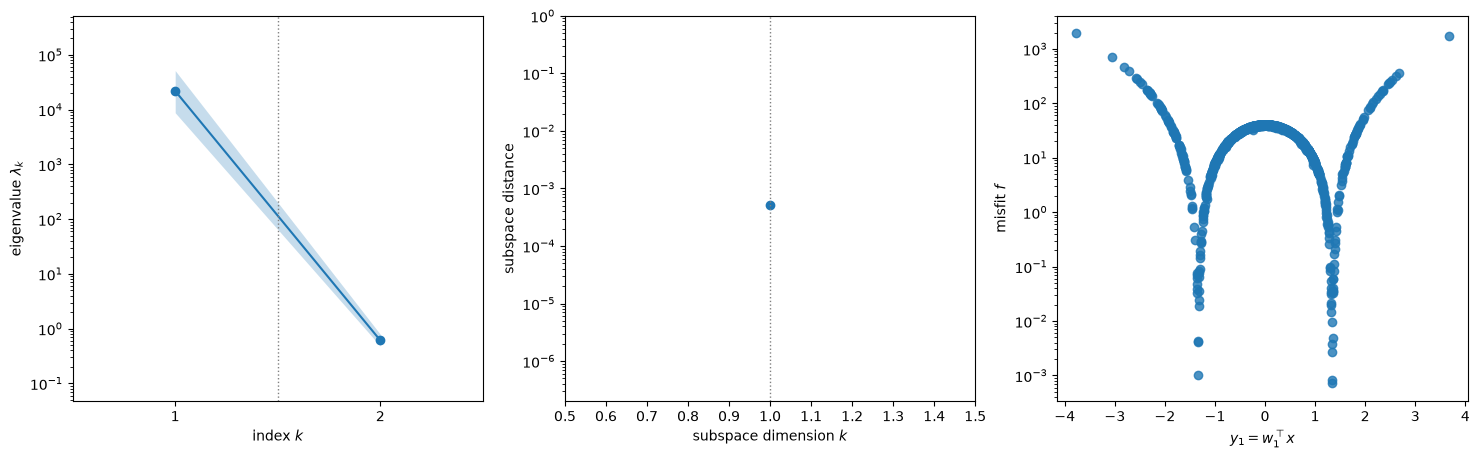

In [3]:
X_grad2 = rng.standard_normal((1000, 2))
sub2 = ac.active_subspace(space=space2, grads=grad_f_quad(X_grad2), nboot=500, rng=rng)
sub2 = ac.orient(sub2, by='reference', reference=np.eye(2)[:, [0, 0]], columns=2)

p50, w50 = np.polynomial.hermite_e.hermegauss(50)
X_gh = np.array(np.meshgrid(p50, p50, indexing='ij')).reshape(2, -1).T
w_gh = np.outer(w50, w50).ravel() / (2*np.pi)
sub2_gh = ac.active_subspace(space=space2, grads=grad_f_quad(X_gh), quad_weights=w_gh)
print(f'Monte Carlo (N = 1000): eigenvalues {sub2.eigenvalues[0]:.4g}, {sub2.eigenvalues[1]:.3g}; '
      f'n = {sub2.n}; w1 = {np.round(sub2.W[:, 0], 4)}')
print(f'50 x 50 Gauss-Hermite:  eigenvalues {sub2_gh.eigenvalues[0]:.4g}, {sub2_gh.eigenvalues[1]:.3g} '
      f'(paper Fig. 5.1(a): about 2e4 and 0.7)')

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
ac.plotting.plot_eigenvalues(sub2, interval='minmax', ax=axes[0])
ac.plotting.plot_subspace_errors(sub2, interval='minmax', ax=axes[1])
ac.plotting.plot_sufficient_summary(sub2, X=X_grad2, f=f_quad(X_grad2), qoi_label='misfit $f$', ax=axes[2])
axes[2].set_yscale('log')
plt.show()

The two eigenvalues differ by more than four orders of magnitude, and the bootstrap subspace error is small: v1's default rule picks $n = 1$, a one-dimensional active subspace. The sufficient summary plot confirms it: the misfit is a tight function of the active variable $\hat y = \hat{\mathbf w}_1^T\mathbf x$, with its minima at two values of $\hat y$ of opposite sign. The Gauss–Hermite eigenvalues agree with [[1]](https://doi.org/10.1137/15M1042127) Fig. 5.1(a).

We now perform standard Metropolis-Hastings MCMC on $\mathbf x$ with a normal proposal centered at the current state and covariance $.5\mathbf I$, for $10^6$ steps from $\mathbf x = [1, 1]^T$, as in [[1]](https://doi.org/10.1137/15M1042127).

vanilla MCMC: 1000000 steps in 11 s, acceptance rate 0.1186 (paper: 12%)


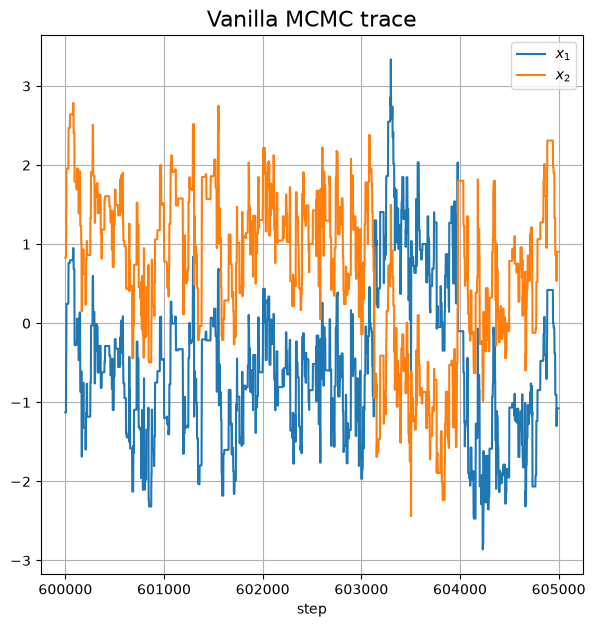

In [4]:
N_quad = 10**6
t0 = time.perf_counter()
X_van2, f_van2, acc_van2 = random_walk_metropolis(lambda x: f_quad(x), np.array([1., 1.]), N_quad,
                                                  np.sqrt(.5), rng)
print(f'vanilla MCMC: {N_quad} steps in {time.perf_counter() - t0:.0f} s, '
      f'acceptance rate {acc_van2.mean():.4f} (paper: 12%)')

steps = np.arange(600_000, 605_000)     # the window of the paper's Fig. 5.2(d)
plt.figure(figsize=(7, 7))
plt.plot(steps, X_van2[steps, 0], steps, X_van2[steps, 1])
plt.grid(True)
plt.xlabel('step')
plt.title('Vanilla MCMC trace', fontsize=16)
plt.legend([r'$x_1$', r'$x_2$'])
plt.show()

We can see significant autocorrelation and cross-correlation in these samples.

Now we perform Metropolis-Hastings on the active variable $\hat y$ ($n = 1$) with $10^5$ steps, one order of magnitude fewer than for vanilla MCMC, from $\hat y = 1$; the proposal is normal with variance $.5$. Here $\hat z$ also has one component, and its conditional density given $\hat y$ is standard Gaussian, so, as in [[1]](https://doi.org/10.1137/15M1042127), we compute $\hat g_\varepsilon(\hat y)$ with a 10-point Gauss–Hermite quadrature rule in $\hat z$ instead of Monte Carlo. Each step then uses 10 forward model evaluations, so the total number of forward model evaluations, $10^6$, is the same as for vanilla MCMC.

In [5]:
sub2_1 = ac.with_dimension(sub2, 1)
p10, w10 = np.polynomial.hermite_e.hermegauss(10)
quad_sampler = ActiveSubspaceMCMC(lambda x: f_quad(x), sub2_1.W1, sub2_1.W2,
                                  z_rule=(p10[:, None], w10 / np.sqrt(2*np.pi)))
t0 = time.perf_counter()
Y2, ghat2, acc_as2 = quad_sampler.sample_active_variables(np.array([1.]), N_quad // 10, 10,
                                                          np.sqrt(.5), rng)
print(f'active subspace MCMC: {N_quad // 10} steps in {time.perf_counter() - t0:.0f} s, '
      f'acceptance rate {acc_as2.mean():.4f} (paper: 13%)')

active subspace MCMC: 100000 steps in 5 s, acceptance rate 0.1343 (paper: 13%)


For each $\hat y$ in our chain, we sample $P = 10$ values of $\hat z$ from the prior and compute $\mathbf x = \hat{\mathbf W}_1\hat y + \hat{\mathbf W}_2 \hat z$, giving us a chain of $10^6$ samples of $\mathbf x$. Below are trace plots of $\mathbf x$ and of $\hat y$, over the windows of [[1]](https://doi.org/10.1137/15M1042127) Fig. 5.2(e) and (f).

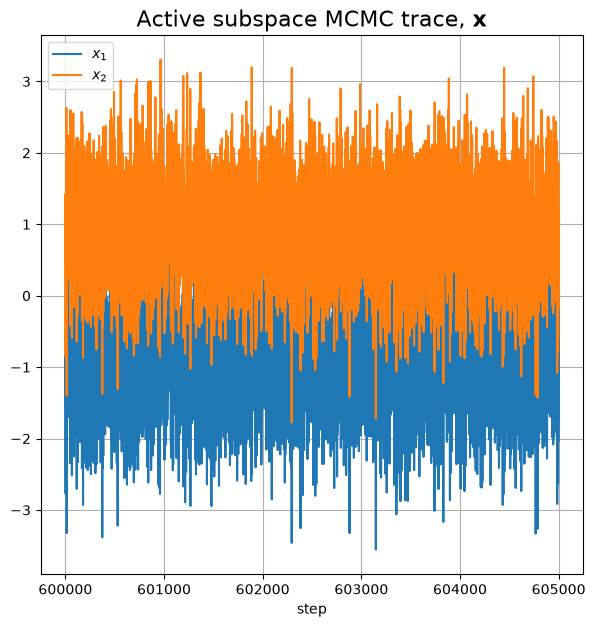

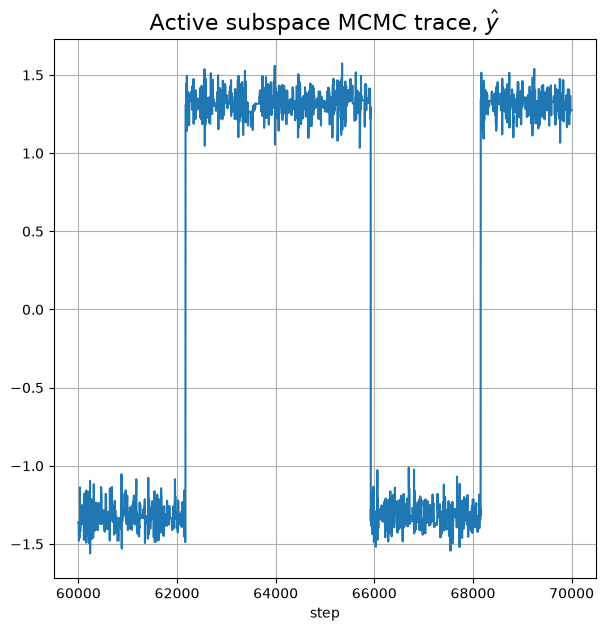

In [6]:
X_as2 = quad_sampler.sample_original_variables(Y2, 10, rng)

plt.figure(figsize=(7, 7))
plt.plot(steps, X_as2[steps, 0], steps, X_as2[steps, 1])
plt.grid(True)
plt.xlabel('step')
plt.title(r'Active subspace MCMC trace, $\mathbf{x}$', fontsize=16)
plt.legend([r'$x_1$', r'$x_2$'])

steps_y = np.arange(60_000, 70_000)
plt.figure(figsize=(7, 7))
plt.plot(steps_y, Y2[steps_y, 0])
plt.grid(True)
plt.xlabel('step')
plt.title(r'Active subspace MCMC trace, $\hat y$', fontsize=16)
plt.show()

There is much less correlation in the samples of $\mathbf x$ than with vanilla MCMC, because the $\hat z$'s are sampled independently. We have a much better chain on $\mathbf x$ for the same number of forward model evaluations by using the active subspace.

Next we compare the posterior densities of both chains on $\mathbf x$, and of the active-variable chain on $\hat y$, using all steps as [[1]](https://doi.org/10.1137/15M1042127) does. The densities are binned Gaussian kernel estimates: a histogram on a grid with spacing 0.02, smoothed by a Gaussian with standard deviation 0.05. (`scipy.stats.gaussian_kde` on $10^6$ points takes minutes, and its default bandwidth, scaled by the spread of both lobes together, blurs the narrow lobes.) We also print the share of samples with $\hat y = \hat{\mathbf w}_1^T\mathbf x > 0$, the lobe on one side of the origin.

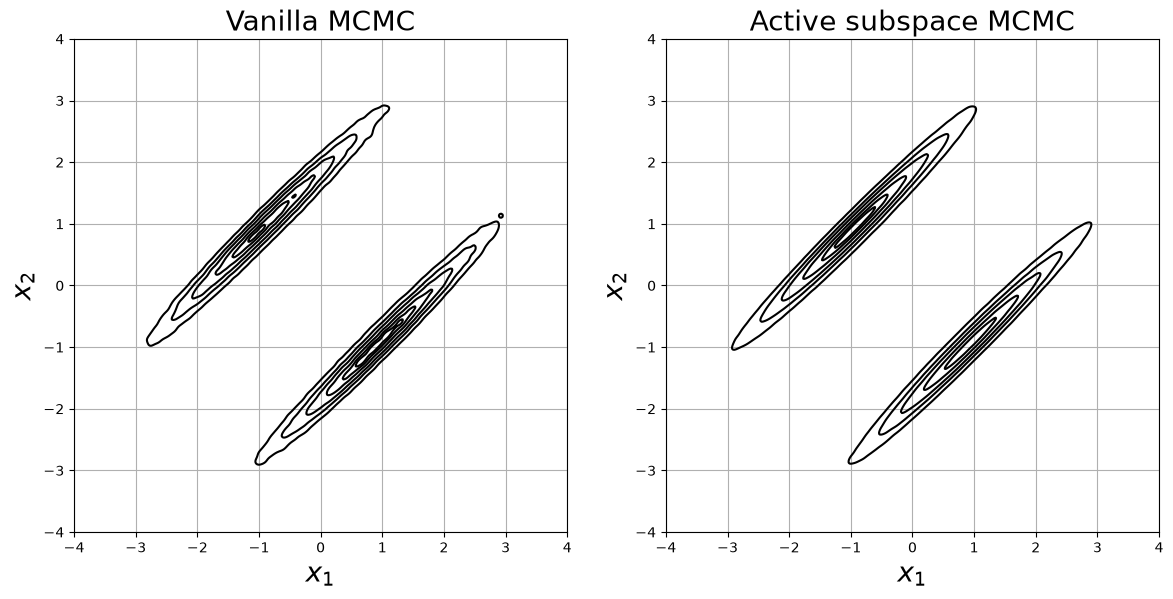

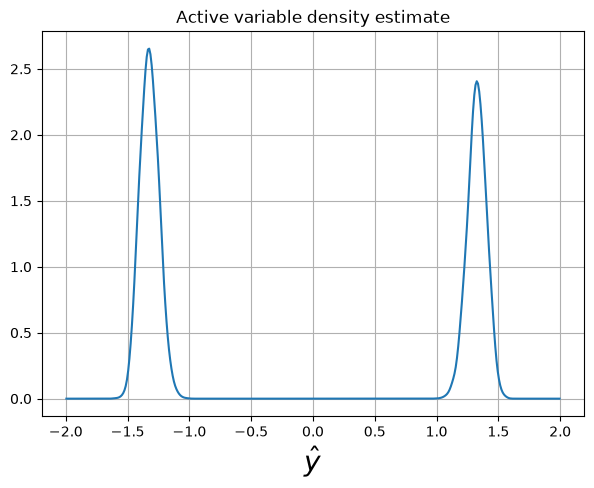

share with w1^T x > 0: vanilla 0.519, active subspace (reconstructed x) 0.467


In [7]:
lims = [(-4, 4), (-4, 4)]
(c1, c2), dens_van = density(X_van2, lims, .02, .05)
_, dens_as = density(X_as2, lims, .02, .05)
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, dens, title in [(axes[0], dens_van, 'Vanilla MCMC'), (axes[1], dens_as, 'Active subspace MCMC')]:
    ax.contour(c1, c2, dens.T, levels=dens.max()*LEVELS, colors="k")
    ax.set_xlim(*lims[0]); ax.set_ylim(*lims[1]); ax.set_aspect('equal')
    ax.grid(True)
    ax.set_xlabel(r'$x_1$', fontsize=20); ax.set_ylabel(r'$x_2$', fontsize=20)
    ax.set_title(title, fontsize=20)

(cy,), dens_y = density(Y2[:, 0], [(-2, 2)], .01, .02)
plt.figure(figsize=(7, 5))
plt.plot(cy, dens_y)
plt.grid(True)
plt.xlabel(r'$\hat y$', fontsize=20)
plt.title('Active variable density estimate')
plt.show()

w1_2 = sub2.W[:, 0]
print(f'share with w1^T x > 0: vanilla {np.mean(X_van2 @ w1_2 > 0):.3f}, '
      f'active subspace (reconstructed x) {np.mean(X_as2 @ w1_2 > 0):.3f}')

Both chains find the two separated lobes of the posterior ([[1]](https://doi.org/10.1137/15M1042127) Fig. 5.1(b)) and put roughly half of their samples in each, and the contours from the active subspace chain agree with those of vanilla MCMC. The density of $\hat y$ has the two narrow peaks of [[1]](https://doi.org/10.1137/15M1042127) Fig. 5.2(c).

### A PDE model with 100 parameters

The second example is a PDE forward model. The PDE is

$$
-\nabla_{\mathbf s}\cdot(a(\mathbf s, \mathbf x)\nabla_{\mathbf s}u) = 1,\ \ \ \mathbf s = [s_1, s_2]^T\in[0, 1]^2,
$$

where $u$ is the solution and $\mathbf s$ are the spatial coordinates, with $u = 0$ on the bottom ($s_2 = 0$), left ($s_1 = 0$) and top ($s_2 = 1$) of the domain, and a zero-flux (homogeneous Neumann) condition on the right ($s_1 = 1$). The log of the coefficient $a$ is a truncated Karhunen–Loève series,

$$
\log(a(\mathbf s, \mathbf x)) = \sum_{i=1}^{m} \sqrt{\sigma_i}\,\phi_i(\mathbf s)\,x_i,
$$

with $m = 100$ terms, where $(\sigma_i, \phi_i)$ are the eigenpairs of the correlation function $\mathcal C(\mathbf s, \mathbf t) = \exp(-\|\mathbf s - \mathbf t\|_1/\beta)$ with $\beta = 0.02$, as in [[1]](https://doi.org/10.1137/15M1042127) eq. (5.5). The eigenpairs are those of the discrete covariance matrix on the $100\times 100$ grid of cell centres, stored in `kl-short.npz` (the same file as in `../Elliptic_PDE_Random_Coefficients`, whose notebook writes this kernel as $\exp(-\|\mathbf s - \mathbf t\|_1/(2\beta))$ with $\beta = .01$). The prior on $\mathbf x$ is standard Gaussian.

The data are noisy observations of $u$ at seven points next to the right boundary: $s_2 = 0.2, 0.3, \dots, 0.8$, at $s_1 = 0.99$, one grid spacing inside the boundary, where [[1]](https://doi.org/10.1137/15M1042127) puts them on it ($s_1 = 1$). The forward model $\mathbf m(\mathbf x)$ returns $u$ at these points. To generate synthetic data, we draw a true value $\mathbf x_{\text{true}}$ from the prior, compute $\mathbf m(\mathbf x_{\text{true}})$, and add Gaussian noise with variance $\sigma^2 = 10^{-4}\|\mathbf m(\mathbf x_{\text{true}})\|^2$, roughly 1% noise, as in [[1]](https://doi.org/10.1137/15M1042127).

**Discretization.** `pde_model.py` (class `PDEMisfit`) solves the PDE with a five-point, vertex-centred finite-volume scheme on a $100\times 100$ grid of cells; [[1]](https://doi.org/10.1137/15M1042127) describes second-order finite differences with 100 points in each dimension. The coefficient $a$ is constant on each cell, and its value on a cell face is the average of the two cells next to it. The unknowns are the $99\times 99$ interior vertices, and the Neumann condition copies the last column of unknowns onto the right boundary (first order). The discrete system is $\mathbf A(\mathbf x)\mathbf u = \mathbf 1$ with $\mathbf A$ symmetric and positive definite. The misfit gradient comes from one adjoint solve, $\mathbf A^T\boldsymbol\lambda = \partial f/\partial\mathbf u$, which reuses the sparse LU factorization of the forward solve, so a misfit and its gradient cost about as much as one solve (timed below). ([[1]](https://doi.org/10.1137/15M1042127) used Wang's `numpad` automatic differentiation package; this code uses only numpy and scipy.)

**Stored chains.** The chains below take hours of computing, so `generate_data.py` runs them once, from saved seeds, and stores them in `pde_mcmc_chains.npz` with everything needed to check them: $\mathbf x_{\text{true}}$, $\mathbf d$, $\sigma^2$, the 1000 points and misfit gradients used for the active subspace, the eigenvectors $\hat{\mathbf W}$ used by the active-variable chains, and the misfit on a grid described below. We load the file, set up the model with the stored data, and check the model against the stored gradients.

In [8]:
import generate_data
from as_mcmc import chain_diagnostics
from pde_model import PDEMisfit

z = np.load('pde_mcmc_chains.npz')
model = PDEMisfit()
model.set_data(z['d'], float(z['sig2']))
x_true = z['x_true']

obs_true = model.observations(x_true)
print(f'sensors at s1 = {z["sensor_s1"][0]:.2f}, s2 = {np.round(z["sensor_s2"], 2)}')
print(f'sigma^2 = {model.sig2:.4e}; noise ||d - m(x_true)|| / ||m(x_true)|| = '
      f'{np.linalg.norm(model.d - obs_true) / np.linalg.norm(obs_true):.4f}')

x, h, coords = z['X_grad'][0], 1e-5, [0, 1, 2, 5]
g = model.misfit_grad(x)
fd = np.array([(model.misfit(x + h*e) - model.misfit(x - h*e)) / (2*h) for e in np.eye(model.m)[coords]])
print(f'misfit gradient at the first stored point: max relative difference from the stored one '
      f'{np.max(np.abs(g - z["G"][0])) / np.max(np.abs(z["G"][0])):.1e}; '
      f'central FD vs adjoint relative error <= {np.max(np.abs(fd - g[coords]) / np.abs(g[coords])):.1e}')
t0 = time.perf_counter()
for xx in z['X_grad'][:20]:
    model.misfit_grad(xx)
print(f'{(time.perf_counter() - t0) / 20 * 1e3:.0f} ms per misfit and gradient')

sensors at s1 = 0.99, s2 = [0.2 0.3 0.4 0.5 0.6 0.7 0.8]
sigma^2 = 6.2996e-06; noise ||d - m(x_true)|| / ||m(x_true)|| = 0.0278


misfit gradient at the first stored point: max relative difference from the stored one 1.9e-13; central FD vs adjoint relative error <= 1.1e-07


18 ms per misfit and gradient


Now we compute the active subspace from the $N = 1000$ stored misfit gradients, which `generate_data.py` computed at prior samples. The default dimension rule in v1 (the largest gap $\lambda_n - \lambda_{n+1}$) picks $n = 1$ here; like [[1]](https://doi.org/10.1137/15M1042127), we choose $n = 2$, which leaves only $\lambda_3, \dots, \lambda_{100}$ in the error bound. We check that the eigenvectors equal the stored ones, which the active-variable chains used.

default rule: n = 1; chosen: n = 2
eigenvalues 1-4: [1794.8  139.3   27.4   12.1]; ratios lambda_1/lambda_2 = 12.9, lambda_2/lambda_3 = 5.1
|cos| between recomputed and stored w1, w2: [1. 1.]; ||W1^T W1 - I|| = 1.6e-15


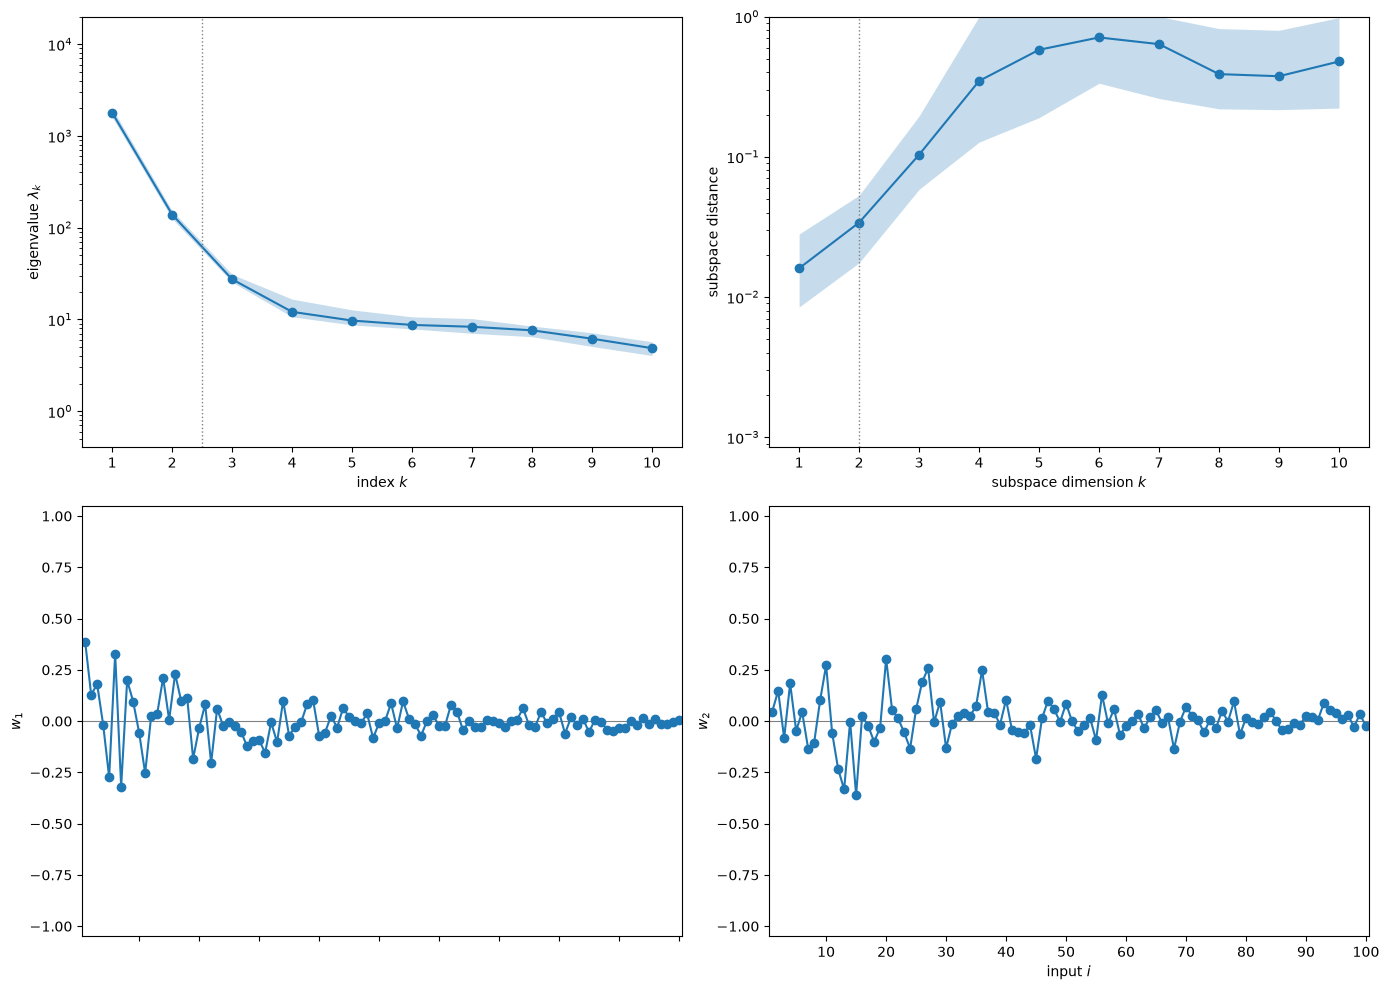

In [9]:
space = ac.Gaussian.reference(100)
sub_default = ac.active_subspace(space=space, grads=z['G'])
sub = ac.active_subspace(space=space, grads=z['G'], nboot=100, rng=rng, n=2)
sub = ac.orient(sub, by='reference', reference=np.eye(100)[:, [0, 0]], columns=2)
lam = sub.eigenvalues
W = z['W']
print(f'default rule: n = {sub_default.n}; chosen: n = {sub.n}')
print(f'eigenvalues 1-4: {np.round(lam[:4], 1)}; ratios lambda_1/lambda_2 = {lam[0] / lam[1]:.1f}, '
      f'lambda_2/lambda_3 = {lam[1] / lam[2]:.1f}')
print(f'|cos| between recomputed and stored w1, w2: '
      f'{np.abs(np.sum(sub.W[:, :2] * W[:, :2], axis=0))}; '
      f'||W1^T W1 - I|| = {np.linalg.norm(W[:, :2].T @ W[:, :2] - np.eye(2)):.1e}')

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
ac.plotting.plot_eigenvalues(sub, k_max=10, interval='minmax', ax=axes[0, 0])
ac.plotting.plot_subspace_errors(sub, k_max=10, interval='minmax', ax=axes[0, 1])
ac.plotting.plot_eigenvectors(sub, indices=[0, 1], ax=[axes[1, 0], axes[1, 1]])
fig.tight_layout()
plt.show()

We find gaps after the first and the second eigenvalues (the ratios are printed above) and small bootstrap subspace errors for one and two dimensions, as in [[1]](https://doi.org/10.1137/15M1042127) Fig. 5.5, so we use a two-dimensional active subspace. Like [[1]](https://doi.org/10.1137/15M1042127) Fig. 5.6(a)–(b), the eigenvectors put most of their weight on the leading Karhunen–Loève coefficients. The recomputed eigenvectors equal the stored ones.

The 100 inputs have little physical meaning by themselves, but we can examine sensitivity by plugging an eigenvector into $\mathbf x$ in the Karhunen–Loève series: $\sum_i \sqrt{\sigma_i}\,\phi_i(\mathbf s)\,w_{ij}$ is the perturbation of the log-coefficient $\log(a)$ along $\mathbf w_j$, as in [[1]](https://doi.org/10.1137/15M1042127) Fig. 5.6. We plot it for the first two eigenvectors, with the sensor locations as dots.

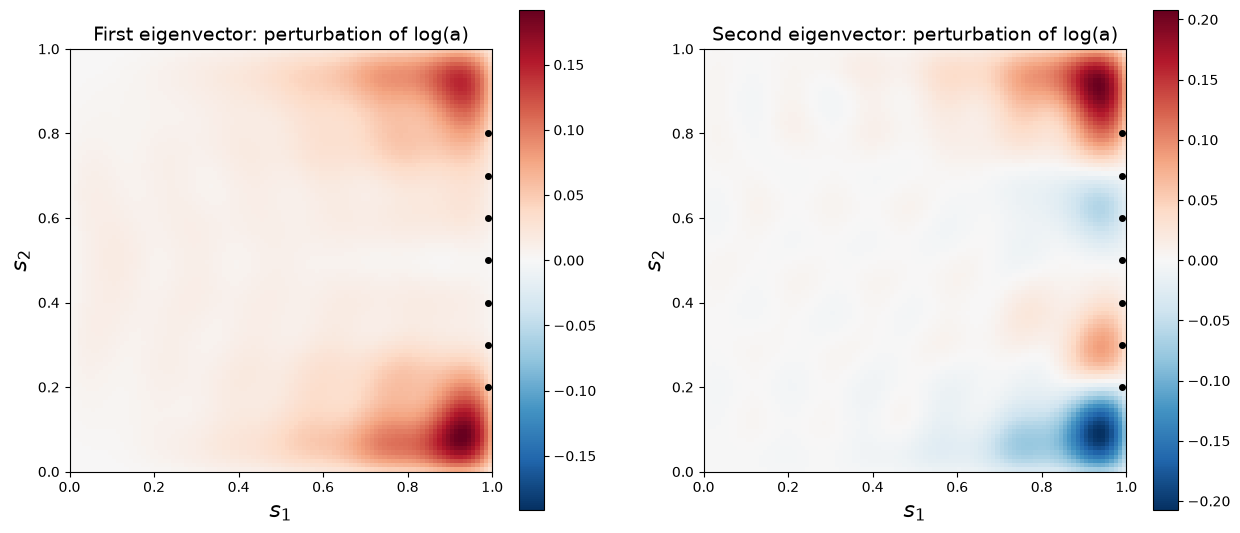

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for j, ax in enumerate(axes):
    field = (model.B @ W[:, j]).reshape(model.nx, model.nx)   # rows: s2, columns: s1
    vmax = np.abs(field).max()
    im = ax.imshow(field, origin='lower', extent=[0, 1, 0, 1], cmap='RdBu_r', vmin=-vmax, vmax=vmax)
    ax.plot(z['sensor_s1'], z['sensor_s2'], 'ko', ms=4)
    ax.set_xlabel(r'$s_1$', fontsize=16); ax.set_ylabel(r'$s_2$', fontsize=16)
    ax.set_title(['First', 'Second'][j] + ' eigenvector: perturbation of log(a)', fontsize=14)
    fig.colorbar(im, ax=ax)
plt.show()

As in [[1]](https://doi.org/10.1137/15M1042127) Fig. 5.6(c)–(d), the misfit is most sensitive to the coefficient near the right boundary, where the observations are, and most of all near its top and bottom corners. The second eigenvector contrasts the bottom corner with the top one.

### The stored chains, and how this study departs from [[1]](https://doi.org/10.1137/15M1042127)

`generate_data.py` ran three samplers as independent chains, each with its own saved seed and started at an independent draw from the prior (which is wide compared with the posterior), with the first 20% of each chain discarded as burn-in, as in [[1]](https://doi.org/10.1137/15M1042127):

- **vanilla**: Metropolis-Hastings on all 100 parameters, proposal standard deviation 0.1, 20 chains of 100,000 steps;
- **cached**: Metropolis-Hastings on $\hat{\mathbf y}$ with $\hat g_\varepsilon$ ($M = 10$) kept with the state, Algorithm 1 as printed in [[1]](https://doi.org/10.1137/15M1042127), 4 chains of 16,000 steps;
- **recompute**: the same with $\hat g_\varepsilon$ recomputed at the current state and at the proposal at every step, the 2016 code that produced [[1]](https://doi.org/10.1137/15M1042127)'s results, 4 chains of 5,000 steps.

The aim is the right answer for this problem, so the study departs from [[1]](https://doi.org/10.1137/15M1042127) where that helps; every departure is listed here.

1. **Data and model**: different synthetic data, sensors at $s_1 = 0.99$, and a finite-volume solver (above).
2. **Two active-variable samplers.** [[1]](https://doi.org/10.1137/15M1042127) prints Algorithm 1 (cached) but computed its results with the recompute variant; we run and report both. [[1]](https://doi.org/10.1137/15M1042127) Table 5.1 counts 500k forward model evaluations for 50k active-variable steps, $M$ per step, which is the cost of Algorithm 1 as printed; the recompute code costs $2M$ per step, 1M evaluations for 50k steps.
3. **Proposal on $\hat{\mathbf y}$.** [[1]](https://doi.org/10.1137/15M1042127) uses an isotropic Gaussian proposal with standard deviation 0.1 (it says "variance"; Table 5.1 also lists 0.3, and its proposal-variance row, 0.3 and 0.1, contradicts its column headings, "AS2, 0.1" and "AS2, 0.3"). Here the proposal is $\hat{\mathbf y}' = \hat{\mathbf y} + s\,\mathbf L\mathbf e$, $\mathbf e \sim N(0, \mathbf I_2)$, where $\mathbf L\mathbf L^T$ is the posterior covariance of $\hat{\mathbf y}$ estimated from vanilla chain 1. The scale $s$ was chosen by pilot runs (`tune_proposal.py`; the table is in `DATA.md`) to minimize the autocorrelation time: $s = 1.2$ for cached and $s = 1.7$ for recompute (printed below). The proposal is fixed during the stored runs. With standard deviation 0.1 the chains mix slowly (autocorrelation times of 100–200 steps for $\hat y_2$).
4. **Chain lengths and number.** [[1]](https://doi.org/10.1137/15M1042127) ran one vanilla chain of 500,000 steps and one active-variable chain of 50,000 steps per variant. Here each active-variable sampler has 4 chains, long enough for an effective sample size of at least 1000 for $\hat y_1$ and $\hat y_2$, and vanilla MCMC has 20 chains of 100,000 steps; split $\hat R$ checks that the chains agree. (The first run had 4 vanilla chains. Their $\hat R$ for $\hat y_2$ was 1.011, and the spread of the 4 chain means suggested a standard error twice the one computed, so 16 chains were added; `DATA.md` has the history.)
5. **Standard errors** come from the autocorrelation (Geyer's initial monotone sequence, combined across chains), not from batch means with short batches.
6. **Reference densities.** The chains are also compared with $\pi_\varepsilon$ and $\pi_M$ (defined below), computed on a grid; [[1]](https://doi.org/10.1137/15M1042127) compares only with the vanilla chain.
7. The proposal for vanilla MCMC, $M = 10$, $P = 10$ and the 20% burn-in are as in [[1]](https://doi.org/10.1137/15M1042127).

Every random draw of a chain comes from its own seeded stream, one step at a time, so a shorter run reproduces the start of a longer one. Before using the stored chains, we rerun the first 1000 steps of vanilla chain 1, 100 steps of cached chain 1 and 50 steps of recompute chain 1 with the generator's code and seeds (about a minute), and compare them with the stored chains. The stored chains were computed on Linux (an AWS c7a instance; the versions are stored in the file). On another machine the floating-point rounding differs, so the rerun agrees to about $10^{-13}$, not bit for bit, and makes the same accept/reject decisions.

In [11]:
t0 = time.perf_counter()
streams = generate_data.streams(int(z['seed']))
live = {'vanilla': generate_data.run_vanilla(model.d, model.sig2, W, streams['vanilla_1'], N=1000),
        'cached': generate_data.run_active(model.d, model.sig2, W, streams['cached_1'], 100, False),
        'recompute': generate_data.run_active(model.d, model.sig2, W, streams['recompute_1'], 50, True)}
print(f'reran in {time.perf_counter() - t0:.0f} s')
checks = [('vanilla', 'trace', 1000), ('vanilla', 'misfit', 100), ('vanilla', 'accept', 1000),
          ('cached', 'y', 100), ('cached', 'ghat', 100), ('cached', 'accept', 100),
          ('recompute', 'y', 50), ('recompute', 'ghat', 50), ('recompute', 'accept', 50)]
for kind, f, n in checks:
    a, b = live[kind][f], z[f'{kind}_1_{f}'][:n]
    print(f'{kind:>10} {f:>7}: max |live - stored| = {np.max(np.abs(a.astype(float) - b.astype(float))):.1e}')

reran in 50 s
   vanilla   trace: max |live - stored| = 0.0e+00
   vanilla  misfit: max |live - stored| = 4.8e-12
   vanilla  accept: max |live - stored| = 0.0e+00
    cached       y: max |live - stored| = 5.6e-17
    cached    ghat: max |live - stored| = 4.0e-12
    cached  accept: max |live - stored| = 0.0e+00
 recompute       y: max |live - stored| = 1.1e-16
 recompute    ghat: max |live - stored| = 1.9e-12
 recompute  accept: max |live - stored| = 0.0e+00


Now we load all chains and discard the burn-in. For each sampler we print the acceptance rate, and for $\hat y_1$ and $\hat y_2$ the autocorrelation time $\tau$ (in steps), the effective sample size (ESS) of all of the sampler's chains together, split $\hat R$ (close to 1 when the chains agree), the mean with its standard error, and the standard deviation. The vanilla values are for $\hat{\mathbf y} = \hat{\mathbf W}_1^T\mathbf x$ along the vanilla chains, stored at every 10th step; the posterior of $\hat{\mathbf y}$ under the exact posterior.

In [12]:
K = {kind: sum(1 for f in z.files if f.startswith(kind + '_') and f.endswith('_accept'))
     for kind in ('vanilla', 'cached', 'recompute')}                      # chains per sampler
burn = float(z['burn_in'])
chains = {}
n_van = len(z['vanilla_1_accept'])
tp = int(z['thin_proj'])
chains['vanilla'] = np.stack([z[f'vanilla_{k}_proj'][int(burn * n_van) // tp:].astype(float)
                              for k in range(1, K['vanilla'] + 1)])         # (K, n, 4), every 10th step
for kind in ('cached', 'recompute'):
    n = len(z[f'{kind}_1_accept'])
    chains[kind] = np.stack([z[f'{kind}_{k}_y'][int(burn * n):] for k in range(1, K[kind] + 1)])
diag = {kind: chain_diagnostics(c[:, :, :2]) for kind, c in chains.items()}
diag['vanilla']['tau'] = diag['vanilla']['tau'] * tp                       # in steps
print(f'proposal for y: L = chol(posterior covariance) = {np.round(z["av_chol"], 4).tolist()}; '
      f's = {float(z["av_scale_cached"])} (cached), {float(z["av_scale_recompute"])} (recompute)')
paper_acc = {'vanilla': '60%', 'cached': '-', 'recompute': '62% (with standard deviation 0.1)'}
for kind in chains:
    n = len(z[f'{kind}_1_accept'])
    acc = np.mean([z[f'{kind}_{k}_accept'].mean() for k in range(1, K[kind] + 1)])
    print(f'{kind}: {K[kind]} chains x {n} steps, acceptance rate {acc:.3f} (paper: {paper_acc[kind]})')
print(f'\n{"":>10}{"":>4}{"tau":>8}{"ESS":>8}{"R-hat":>8}{"mean ± SE":>18}{"std":>8}')
for kind, d in diag.items():
    sd = chains[kind][:, :, :2].reshape(-1, 2).std(axis=0)
    for j in range(2):
        print(f'{kind:>10}{"y_" + str(j + 1):>4}{d["tau"][j]:8.1f}{d["ess"][j]:8.0f}{d["rhat"][j]:8.3f}'
              f'{d["mean"][j]:10.3f} ± {d["se"][j]:.3f}{sd[j]:8.3f}')
y_post = chains['vanilla'].reshape(-1, 4).mean(axis=0)[:2]
g_rep = [ActiveSubspaceMCMC(model.misfit, W[:, :2], W[:, 2:]).ghat(y_post, 10, rng) for _ in range(20)]
print(f'\n20 estimates ghat(y) with M = 10 at the posterior mean of y: mean {np.mean(g_rep):.2f}, '
      f'standard deviation {np.std(g_rep, ddof=1):.2f}')

proposal for y: L = chol(posterior covariance) = [[0.2438, 0.0], [-0.1044, 0.3561]]; s = 1.2 (cached), 1.7 (recompute)
vanilla: 20 chains x 100000 steps, acceptance rate 0.547 (paper: 60%)
cached: 4 chains x 16000 steps, acceptance rate 0.167 (paper: -)
recompute: 4 chains x 5000 steps, acceptance rate 0.313 (paper: 62% (with standard deviation 0.1))

                   tau     ESS   R-hat         mean ± SE     std
   vanilla y_1   228.9    6990   1.004     0.739 ± 0.003   0.241
   vanilla y_2   235.2    6802   1.003    -0.829 ± 0.005   0.376
    cached y_1    26.8    1910   1.002     0.657 ± 0.004   0.180
    cached y_2    24.8    2068   1.002    -0.664 ± 0.007   0.313
 recompute y_1     8.9    1804   1.002     0.643 ± 0.006   0.248
 recompute y_2    10.2    1569   1.002    -0.636 ± 0.011   0.444



20 estimates ghat(y) with M = 10 at the posterior mean of y: mean 10.65, standard deviation 1.61


All three samplers meet the targets: for $\hat y_1$ and $\hat y_2$ the effective sample size is about 7000 for vanilla MCMC (20 chains) and 1600–2100 for each active-variable sampler (4 chains), and split $\hat R \le 1.004$. The autocorrelation times are about 230 vanilla steps, 25 cached steps and 10 recompute steps. Per forward model evaluation the samplers are closer than these numbers suggest, because a cached step costs $M = 10$ evaluations and a recompute step $2M = 20$: an effective sample of $\hat{\mathbf y}$ costs about 230 evaluations with vanilla MCMC, 250–270 with the cached sampler and 180–200 with the recompute sampler. The gain from the active subspace is in $\mathbf x$, whose 98 inactive directions are drawn independently (the trace plots below, and [[1]](https://doi.org/10.1137/15M1042127) Fig. 5.8).

The acceptance rates are lower than [[1]](https://doi.org/10.1137/15M1042127)'s. For vanilla MCMC (0.547 against 60%) the proposal is the same, but the data and the solver differ (departure 1). The active-variable proposals are larger than [[1]](https://doi.org/10.1137/15M1042127)'s, because they were tuned for the autocorrelation time (departure 3). The cached sampler accepts only 17% of its proposals: with $M = 10$, $\hat g_\varepsilon$ at the posterior mean has a standard deviation of 1.6 (printed above), and a state whose estimate came out low keeps that estimate, which proposals rarely beat.

The trace plots show the last 2000 steps of chain 1 of each sampler: $x_{10}$ and $x_{90}$ for vanilla MCMC, $\hat{\mathbf y}$ for both active-variable samplers, and $x_{10}, x_{90}$ reconstructed from the cached chain with $P = 10$ draws of $\hat{\mathbf z}$ per state (the last 200 states).

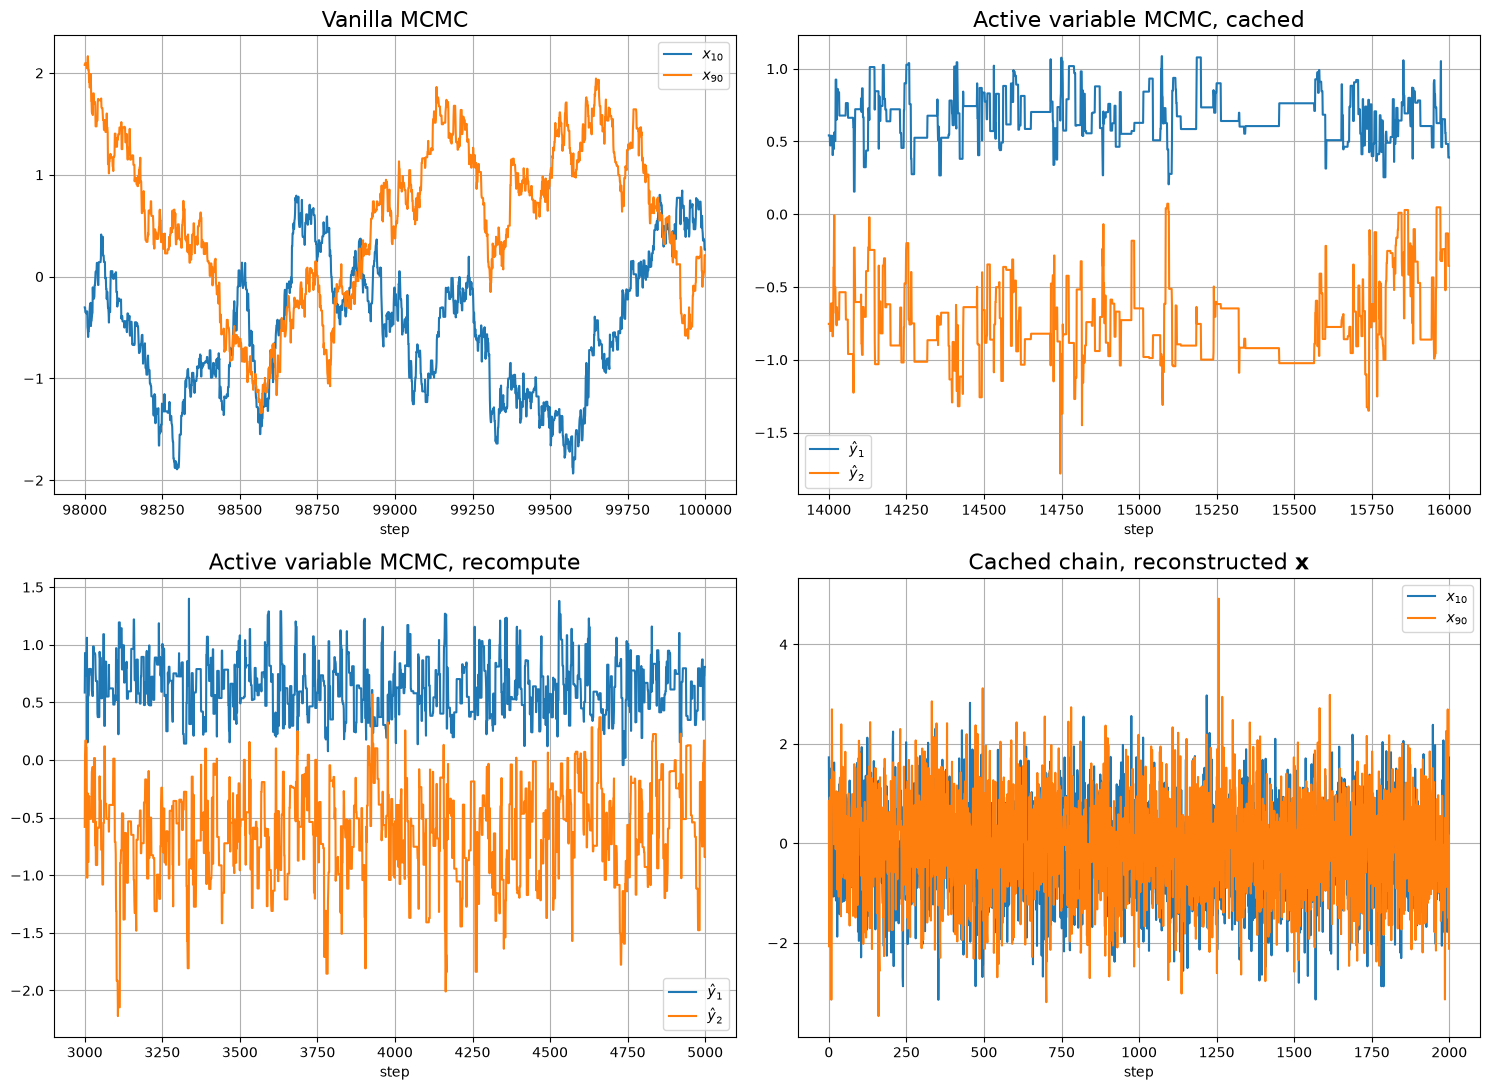

In [13]:
pde_sampler = ActiveSubspaceMCMC(model.misfit, W[:, :2], W[:, 2:])
X_as = pde_sampler.sample_original_variables(z['cached_1_y'][-200:], 10, rng)
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
k = np.arange(n_van - 2000, n_van)
axes[0, 0].plot(k, z['vanilla_1_trace'][k, 0], k, z['vanilla_1_trace'][k, 1])
axes[0, 0].set_title('Vanilla MCMC', fontsize=16)
axes[0, 0].legend([r'$x_{10}$', r'$x_{90}$'])
for ax, kind in [(axes[0, 1], 'cached'), (axes[1, 0], 'recompute')]:
    n = len(z[f'{kind}_1_accept'])
    k = np.arange(n - min(2000, n), n)
    ax.plot(k, z[f'{kind}_1_y'][k, 0], k, z[f'{kind}_1_y'][k, 1])
    ax.set_title(f'Active variable MCMC, {kind}', fontsize=16)
    ax.legend([r'$\hat y_1$', r'$\hat y_2$'])
axes[1, 1].plot(np.arange(len(X_as)), X_as[:, 9], np.arange(len(X_as)), X_as[:, 89])
axes[1, 1].set_title(r'Cached chain, reconstructed $\mathbf{x}$', fontsize=16)
axes[1, 1].legend([r'$x_{10}$', r'$x_{90}$'])
for ax in axes.ravel():
    ax.grid(True); ax.set_xlabel('step')
fig.tight_layout()
plt.show()

### What the active-variable chains approximate

The active-variable chains do not sample the posterior. We compute directly the means of $\hat{\mathbf y}$ under the two densities they approximate:

- $\pi_\varepsilon \propto \exp(-g_\varepsilon(\hat{\mathbf y}))\,\rho_{\text{pri}}(\hat{\mathbf y})$, with the exact conditional mean $g_\varepsilon$ ([[1]](https://doi.org/10.1137/15M1042127) Theorem 3.1);
- $\pi_M \propto \mathbb E\left[\exp(-\hat g_\varepsilon(\hat{\mathbf y}))\right]\rho_{\text{pri}}(\hat{\mathbf y})$, the average over the noise of the estimate from $M = 10$ draws. The cached sampler is a pseudo-marginal method and samples $\pi_M$ exactly; the recompute sampler, Monte Carlo within Metropolis [[4]](https://doi.org/10.1214/07-AOS574), has no closed-form stationary density. $\pi_M$ lies between $\pi_\varepsilon$ and the posterior marginal of $\hat{\mathbf y}$.

`generate_data.py` stored the misfit $f(\hat{\mathbf W}_1\hat{\mathbf y} + \hat{\mathbf W}_2\hat{\mathbf z})$ on a $21\times 21$ grid in $\hat{\mathbf y}$ (about 5 standard deviations of the cached chain on each side of its mean), with the same prior draws $\hat{\mathbf z}$ at every grid point: 160 draws at all points and 2560 at every other point (the $11\times 11$ coarse grid). On the coarse grid, $g_\varepsilon$ is the mean over the 2560 draws, and $\mathbb E[\exp(-\hat g_\varepsilon)]$ is the average of $\exp(-\hat g_\varepsilon)$ over 2000 random 10-draw subsets. The means of $\hat{\mathbf y}$ use the trapezoid rule, and their standard errors come from 200 bootstrap resamples of the draws.

First, a convergence check of the grid: halving the spacing (coarse vs fine grid, same 160 draws), shrinking the extent from 5 to 4 standard deviations (fine grid, 160 draws), and doubling the draws (1280 vs 2560, coarse grid). Each change should move the means much less than the chains' standard errors.

In [14]:
g1, g2 = z['grid_y1'], z['grid_y2']
F_fine, F_coarse = z['grid_f_fine'].astype(float), z['grid_f_coarse'].astype(float)
S_cache = {}


def subsets_for(K, n_sub=2000):
    """2000 random 10-draw subsets of K draws (fixed per K for reproducibility)."""
    if K not in S_cache:
        S_cache[K] = np.array([rng.choice(K, 10, replace=False) for _ in range(n_sub)])
    return S_cache[K]


def loglik(F, kind, S=None):
    """log of exp(-g_eps) or of E[exp(-ghat_10)] at each grid point, from draws F (..., K)."""
    if kind == 'pi_eps':
        return -F.mean(axis=-1)
    S = subsets_for(F.shape[-1]) if S is None else S
    gh = F[..., S].mean(axis=-1)
    g0 = gh.min(axis=-1, keepdims=True)
    return -g0[..., 0] + np.log(np.exp(-(gh - g0)).mean(axis=-1))


def grid_mean(ll, a1, a2):
    """Mean of y under exp(ll) rho on the grid a1 x a2 (trapezoid rule)."""
    A1, A2 = np.meshgrid(a1, a2, indexing='ij')
    w = np.outer(np.r_[.5, np.ones(len(a1) - 2), .5], np.r_[.5, np.ones(len(a2) - 2), .5])
    p = w * np.exp(ll - 0.5*(A1**2 + A2**2) - (ll - 0.5*(A1**2 + A2**2)).max())
    return np.array([(p*A1).sum(), (p*A2).sum()]) / p.sum()


Kf, Kc = F_fine.shape[2], F_coarse.shape[2]
c1, c2 = g1[::2], g2[::2]
inner = slice(2, len(g1) - 2)
print(f'grid {len(g1)} x {len(g2)} (spacing {g1[1] - g1[0]:.3f}, {g2[1] - g2[0]:.3f}), '
      f'{Kf} draws; coarse {len(c1)} x {len(c2)}, {Kc} draws')
print(f'{"change in the mean of (y_1, y_2)":>40}{"pi_eps":>20}{"pi_M":>20}')
rows = {'spacing h -> h/2': [], 'extent: full -> inner 4/5': [], f'draws {Kc // 2} -> {Kc}': []}
for kind in ('pi_eps', 'pi_M'):
    rows['spacing h -> h/2'].append(grid_mean(loglik(F_fine, kind), g1, g2)
                                    - grid_mean(loglik(F_fine[::2, ::2], kind), c1, c2))
    rows[list(rows)[1]].append(grid_mean(loglik(F_fine[inner, inner], kind), g1[inner], g2[inner])
                               - grid_mean(loglik(F_fine, kind), g1, g2))
    rows[list(rows)[2]].append(grid_mean(loglik(F_coarse, kind), c1, c2)
                               - grid_mean(loglik(F_coarse[..., :Kc // 2], kind), c1, c2))
for name, (de, dm) in rows.items():
    print(f'{name:>40}{np.abs(de).max():20.4f}{np.abs(dm).max():20.4f}')

ref = {}
for kind in ('pi_eps', 'pi_M'):
    boot = np.array([grid_mean(loglik(F_coarse[..., rng.integers(0, Kc, Kc)], kind), c1, c2)
                     for _ in range(200)])
    ref[kind] = grid_mean(loglik(F_coarse, kind), c1, c2), boot.std(axis=0, ddof=1)
print(f'bootstrap standard errors (coarse grid, {Kc} draws): pi_eps {np.round(ref["pi_eps"][1], 4)}, '
      f'pi_M {np.round(ref["pi_M"][1], 4)}')
print(f'smallest chain standard error: {min(d["se"].min() for d in diag.values()):.4f}')

grid 21 x 21 (spacing 0.100, 0.170), 160 draws; coarse 11 x 11, 2560 draws
        change in the mean of (y_1, y_2)              pi_eps                pi_M


                        spacing h -> h/2              0.0000              0.0000
               extent: full -> inner 4/5              0.0000              0.0000
                      draws 1280 -> 2560              0.0031              0.0030


bootstrap standard errors (coarse grid, 2560 draws): pi_eps [0.0032 0.0046], pi_M [0.0047 0.0059]
smallest chain standard error: 0.0029


Halving the spacing and shrinking the extent change the means by less than $10^{-4}$, so the grid is fine enough and wide enough. Doubling the draws changes them by 0.003, about the smallest chain standard error. That change is the Monte Carlo error of the grid itself: the difference between half of the draws and all of them should be about the bootstrap standard error of the full set (0.003–0.006), and that standard error enters the comparison below.

Now the comparison. The cached sampler targets $\pi_M$ exactly, so we test it: its mean of $\hat{\mathbf y}$ should agree with the grid's $\pi_M$ mean within $3\,(\mathrm{SE}_{\text{chain}}^2 + \mathrm{SE}_{\text{grid}}^2)^{1/2}$ in each component. The recompute sampler and both active-variable samplers against the vanilla chain (the exact posterior) are compared and reported, not expected to agree: the offsets are printed in units of the combined standard error.

In [15]:
rows = [('vanilla (posterior)', diag['vanilla']['mean'], diag['vanilla']['se']),
        ('pi_eps (grid)', *ref['pi_eps']), ('pi_M, M = 10 (grid)', *ref['pi_M']),
        ('cached chains', diag['cached']['mean'], diag['cached']['se']),
        ('recompute chains', diag['recompute']['mean'], diag['recompute']['se'])]
print(f'{"mean of y":>22}{"y_1":>18}{"y_2":>18}')
for name, mean, se in rows:
    print(f'{name:>22}' + ''.join(f'{mean[j]:10.3f} ± {se[j]:.3f}' for j in range(2)))
table = {name: (mean, se) for name, mean, se in rows}


def offset(a, b):
    (ma, sa), (mb, sb) = table[a], table[b]
    return (ma - mb), (ma - mb) / np.hypot(sa, sb)


print('\nTest: cached chains vs pi_M (pass if |offset| <= 3 combined standard errors)')
diff, zs = offset('cached chains', 'pi_M, M = 10 (grid)')
for j in range(2):
    print(f'  y_{j + 1}: offset {diff[j]:+.3f} = {zs[j]:+.1f} SE: {"pass" if abs(zs[j]) <= 3 else "FAIL"}')
print('Reported (offset, in combined standard errors):')
for a, b in [('recompute chains', 'pi_M, M = 10 (grid)'), ('cached chains', 'vanilla (posterior)'),
             ('recompute chains', 'vanilla (posterior)'), ('pi_eps (grid)', 'vanilla (posterior)')]:
    diff, zs = offset(a, b)
    print(f'  {a} - {b}: ' + ', '.join(f'y_{j + 1} {diff[j]:+.3f} ({zs[j]:+.1f} SE)' for j in range(2)))
print(f'lambda_1 + lambda_2 = {lam[:2].sum():.0f}; lambda_3 + ... + lambda_100 = {lam[2:].sum():.0f}')

             mean of y               y_1               y_2
   vanilla (posterior)     0.739 ± 0.003    -0.829 ± 0.005
         pi_eps (grid)     0.629 ± 0.003    -0.601 ± 0.005
   pi_M, M = 10 (grid)     0.649 ± 0.005    -0.651 ± 0.006
         cached chains     0.657 ± 0.004    -0.664 ± 0.007
      recompute chains     0.643 ± 0.006    -0.636 ± 0.011

Test: cached chains vs pi_M (pass if |offset| <= 3 combined standard errors)
  y_1: offset +0.008 = +1.3 SE: pass
  y_2: offset -0.013 = -1.4 SE: pass
Reported (offset, in combined standard errors):
  recompute chains - pi_M, M = 10 (grid): y_1 -0.005 (-0.7 SE), y_2 +0.015 (+1.2 SE)
  cached chains - vanilla (posterior): y_1 -0.082 (-16.3 SE), y_2 +0.165 (+20.0 SE)
  recompute chains - vanilla (posterior): y_1 -0.095 (-14.6 SE), y_2 +0.193 (+16.0 SE)
  pi_eps (grid) - vanilla (posterior): y_1 -0.109 (-25.4 SE), y_2 +0.228 (+35.1 SE)
lambda_1 + lambda_2 = 1934; lambda_3 + ... + lambda_100 = 124


The cached chains agree with $\pi_M$, the density they sample exactly (offsets of 1.3 and 1.4 combined standard errors), which checks the sampler, the grid and the standard errors together. The recompute chains are also within about one standard error of $\pi_M$. The two variants differ by 0.013 and 0.028, about 2 standard errors, which these chains cannot resolve: at this noise level they give the same answer.

Neither agrees with the posterior. Both active-variable samplers put the mean of $\hat y_1$ 0.08–0.10 lower and the mean of $\hat y_2$ 0.17–0.19 higher than vanilla MCMC: 15–20 combined standard errors, or 0.35–0.5 posterior standard deviations. $\pi_\varepsilon$ is farther still, and averaging $\exp(-\hat g_\varepsilon)$ over the noise ($\pi_M$ instead of $\pi_\varepsilon$) moves the mean 0.02–0.05 toward the posterior. This is the approximation error that Theorem 3.1 bounds, not sampling noise: the inactive eigenvalues, $\lambda_3 + \cdots + \lambda_{100} = 124$, are not small next to $\lambda_1 + \lambda_2 = 1934$, and the data also inform $\hat y_3$ (below). The spreads differ too: the posterior standard deviation of $\hat y_2$ is 0.38, against 0.31 for the cached chains and 0.44 for the recompute chains (printed above). [[1]](https://doi.org/10.1137/15M1042127) compares the samplers only through the moments of $\mathbf x$ (below) and does not report this offset.

Next, as in [[1]](https://doi.org/10.1137/15M1042127) Fig. 5.10, the bivariate posterior marginals of the first four components of $\hat{\mathbf y} = \hat{\mathbf W}^T\mathbf x$ along the vanilla chains (all 20 chains, every 10th step after burn-in).

vanilla posterior means of y_1..y_4: [ 0.74 -0.83 -1.28  0.06], standard deviations: [0.24 0.38 0.53 0.93]


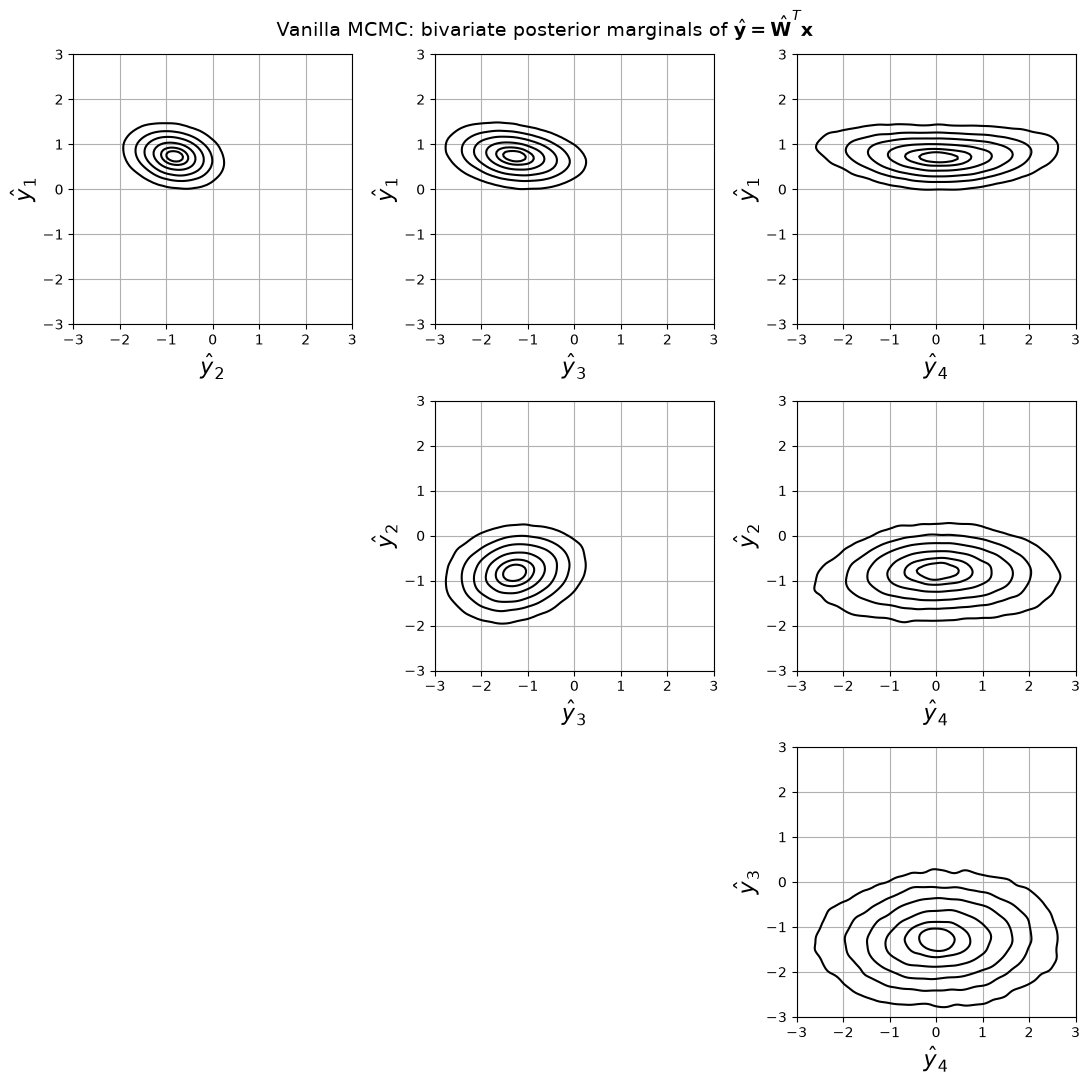

In [16]:
y_van = chains['vanilla'].reshape(-1, 4)
print(f'vanilla posterior means of y_1..y_4: {np.round(y_van.mean(axis=0), 2)}, '
      f'standard deviations: {np.round(y_van.std(axis=0), 2)}')
fig, axes = plt.subplots(3, 3, figsize=(11, 11))
lims = [(-3, 3), (-3, 3)]
for i in range(3):
    for j in range(3):
        ax = axes[i, j]
        if j < i:
            ax.axis('off')
            continue
        (cx, cy), dens = density(y_van[:, [j + 1, i]], lims, .05, .1)
        ax.contour(cx, cy, dens.T, levels=dens.max()*LEVELS, colors="k")
        ax.set_xlim(*lims[0]); ax.set_ylim(*lims[1])
        ax.grid(True)
        ax.set_xlabel(rf'$\hat y_{j + 2}$', fontsize=16); ax.set_ylabel(rf'$\hat y_{i + 1}$', fontsize=16)
fig.suptitle(r'Vanilla MCMC: bivariate posterior marginals of $\hat{\mathbf{y}} = \hat{\mathbf{W}}^T\mathbf{x}$', fontsize=14)
fig.tight_layout()
plt.show()

As in [[1]](https://doi.org/10.1137/15M1042127) Fig. 5.10, the data move and narrow $\hat y_1$ and $\hat y_2$ the most: their posterior standard deviations are 0.24 and 0.38, against 1 under the prior. Unlike [[1]](https://doi.org/10.1137/15M1042127), which finds that $\hat y_3$ and $\hat y_4$ "more closely" resemble the standard Gaussian prior, here $\hat y_3$ is also clearly informed by the data (mean −1.28, standard deviation 0.53); only $\hat y_4$ stays close to its prior (mean 0.06, standard deviation 0.93). The data differ from [[1]](https://doi.org/10.1137/15M1042127)'s (departure 1). The active-variable samplers draw $\hat y_3$ from the prior, so they miss this.

Finally, as in [[1]](https://doi.org/10.1137/15M1042127) Fig. 5.9, we compare the posterior mean and variance of each of the 100 components of $\mathbf x$ from the active-variable samplers with those of the vanilla chains. The vanilla moments use every 50th state of the 20 chains after burn-in, and their 99% intervals use standard errors from the autocorrelation; we print the effective sample sizes. For an active-variable chain, the reconstruction $\mathbf x = \hat{\mathbf W}_1\hat{\mathbf y} + \hat{\mathbf W}_2\hat{\mathbf z}$ with $\hat{\mathbf z}$ from the prior has mean $\hat{\mathbf W}_1\bar{\mathbf y}$ and covariance $\hat{\mathbf W}_1\,\mathrm{Cov}(\hat{\mathbf y})\,\hat{\mathbf W}_1^T + \hat{\mathbf W}_2\hat{\mathbf W}_2^T$; we use these exact averages over $\hat{\mathbf z}$ instead of $P = 10$ random draws per state.

vanilla x: ESS of the means min 1761, median 2201; of the variances min 3622, median 4397; R-hat max 1.016
cached: components inside the vanilla 99% interval: means 44%, variances 84%
recompute: components inside the vanilla 99% interval: means 45%, variances 82%


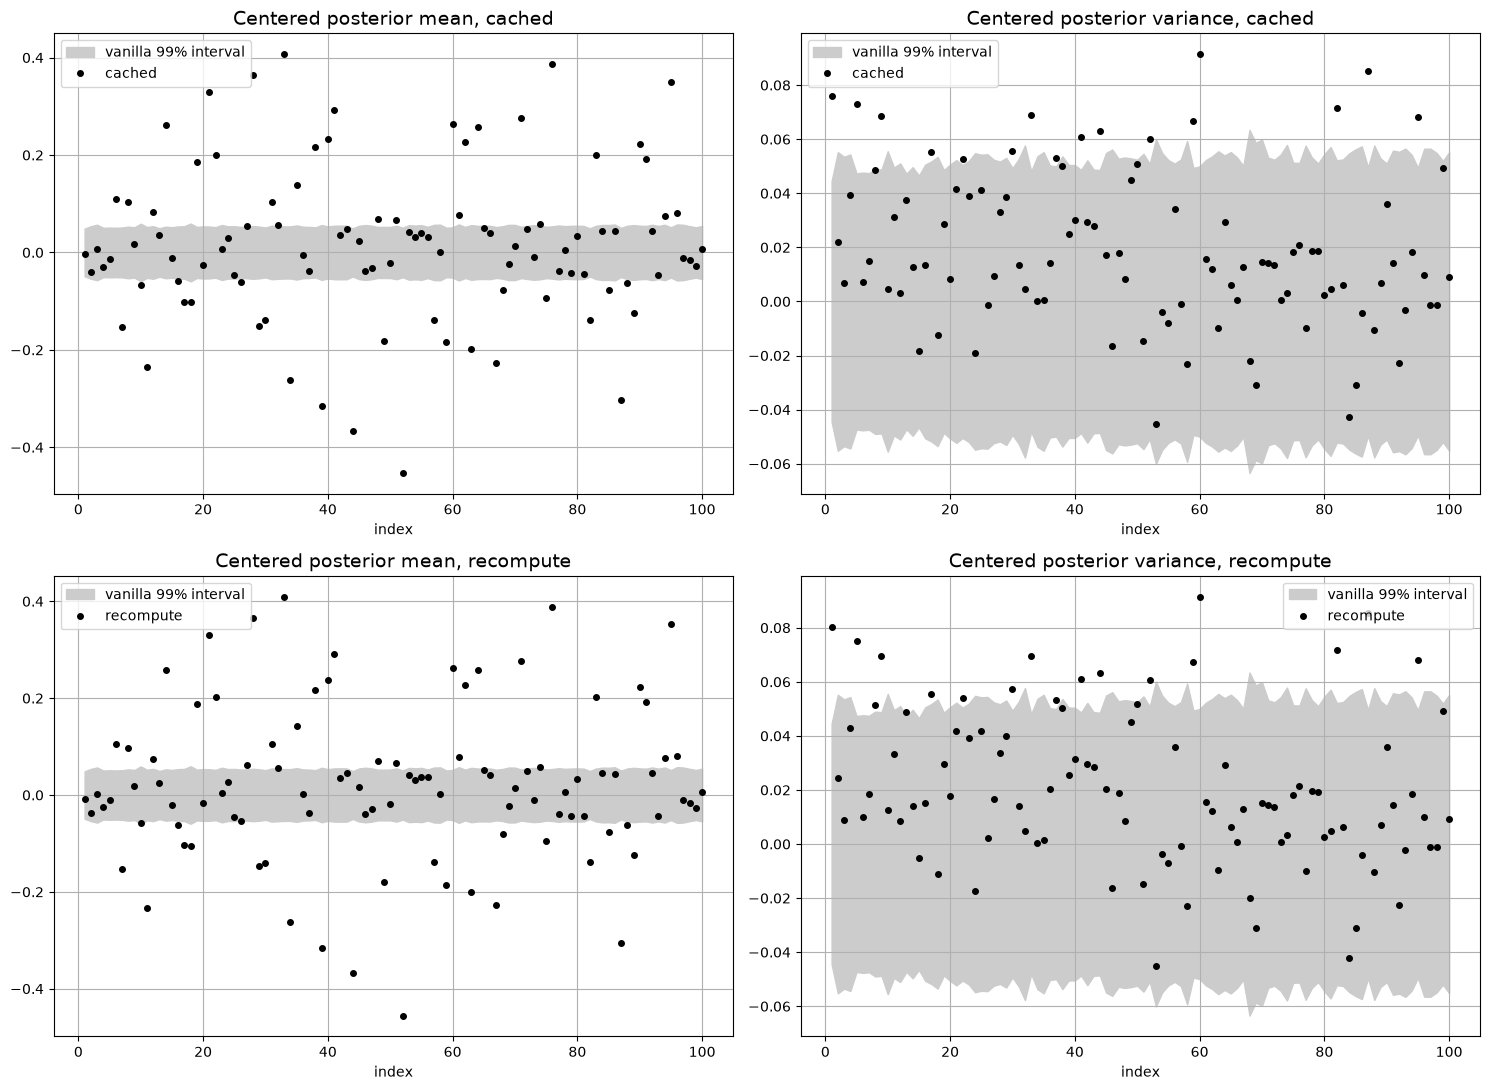

In [17]:
tx = int(z['thin_x'])
X_van = np.stack([z[f'vanilla_{k}_thin'][int(burn * n_van) // tx:].astype(float)
                  for k in range(1, K['vanilla'] + 1)])
d_mu = chain_diagnostics(X_van)
d_var = chain_diagnostics((X_van - d_mu['mean'])**2)
print(f'vanilla x: ESS of the means min {d_mu["ess"].min():.0f}, median {np.median(d_mu["ess"]):.0f}; '
      f'of the variances min {d_var["ess"].min():.0f}, median {np.median(d_var["ess"]):.0f}; '
      f'R-hat max {d_mu["rhat"].max():.3f}')
q = 2.576
W1, W2 = W[:, :2], W[:, 2:]
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
idx = np.arange(1, 101)
for row, kind in enumerate(('cached', 'recompute')):
    Yk = chains[kind].reshape(-1, 2)
    mu = W1 @ Yk.mean(axis=0)
    var = np.einsum('ij,jk,ik->i', W1, np.cov(Yk.T), W1) + (W2**2).sum(axis=1)
    in_mu = np.mean(np.abs(mu - d_mu['mean']) <= q * d_mu['se'])
    in_var = np.mean(np.abs(var - d_var['mean']) <= q * d_var['se'])
    print(f'{kind}: components inside the vanilla 99% interval: means {in_mu:.0%}, variances {in_var:.0%}')
    for ax, diff, hw, name in [(axes[row, 0], mu - d_mu['mean'], q * d_mu['se'], 'mean'),
                               (axes[row, 1], var - d_var['mean'], q * d_var['se'], 'variance')]:
        ax.fill_between(idx, -hw, hw, color='0.8', label='vanilla 99% interval')
        ax.plot(idx, diff, 'ko', ms=4, label=kind)
        ax.grid(True); ax.legend()
        ax.set_xlabel('index'); ax.set_title(f'Centered posterior {name}, {kind}', fontsize=14)
fig.tight_layout()
plt.show()

With 20 vanilla chains, the vanilla 99% intervals have a median half-width of 0.054 for the means, about half of the ±0.1 in [[1]](https://doi.org/10.1137/15M1042127) Fig. 5.9. Only 44% (cached) and 45% (recompute) of the active-variable means fall inside them; 84% and 82% of the variances do. The misses in the means are not noise. Of the squared difference between the active-variable and vanilla means, 99% lies along the inactive directions $\hat{\mathbf w}_3, \dots, \hat{\mathbf w}_{100}$ and 65% along $\hat{\mathbf w}_3$ alone, where the posterior mean of $\hat y_3$ is −1.28 and the reconstruction's is 0. [[1]](https://doi.org/10.1137/15M1042127) reads Fig. 5.9 as "general agreement in the sample moments", with the points outside the intervals a possible sign of bias; with these data and tighter intervals, the bias is clear. (With the first 4 vanilla chains only, 65–66% of the means fell inside the wider intervals.)

We have shown for two forward models that reducing their dimensionality with active subspaces greatly improves the mixing of the chain on $\mathbf x$, because the inactive variables are drawn independently. The price is the error of the approximate posterior, which Theorem 3.1 bounds by the inactive eigenvalues. For the quadratic model that error is small. For the PDE model with these data it is not: the two-dimensional approximation shifts the posterior mean of the active variables by up to half a posterior standard deviation and ignores what the data say about $\hat y_3$. Including $\hat y_3$ in the active variables ($n = 3$) is the natural next step; it was not run here.

In [18]:
print(f'Total run time: {time.perf_counter() - t_start:.0f} s')

Total run time: 79 s
